# Lab 3 – Binaryzacja i wycinanie liścia

Cel: oddzielić liść od tła, żeby dalsza analiza (np. transformata Hougha) patrzyła tylko na liść.
Funkcje są w `leaf_utils.py`, żeby oba notebooki używały tej samej segmentacji.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import color, filters, measure

import leaf_utils as lu

# moc wygładzania konturu: promień dysku [px] dla dylatacji, a potem erozji (0 = bez wygładzania)
SMOOTH_RADIUS = 50

samples = [(label, path, lu.load(path)) for label, path in lu.sample_paths(4)]

## 1. Wybór kanału do progowania

Porównanie trzech kandydatów, każdy progowany metodą Otsu:
- **S** (nasycenie z HSV),
- **ExG** = 2G − R − B (nadmiar zieleni),
- **b\*** z przestrzeni Lab (oś niebiesko-żółta).

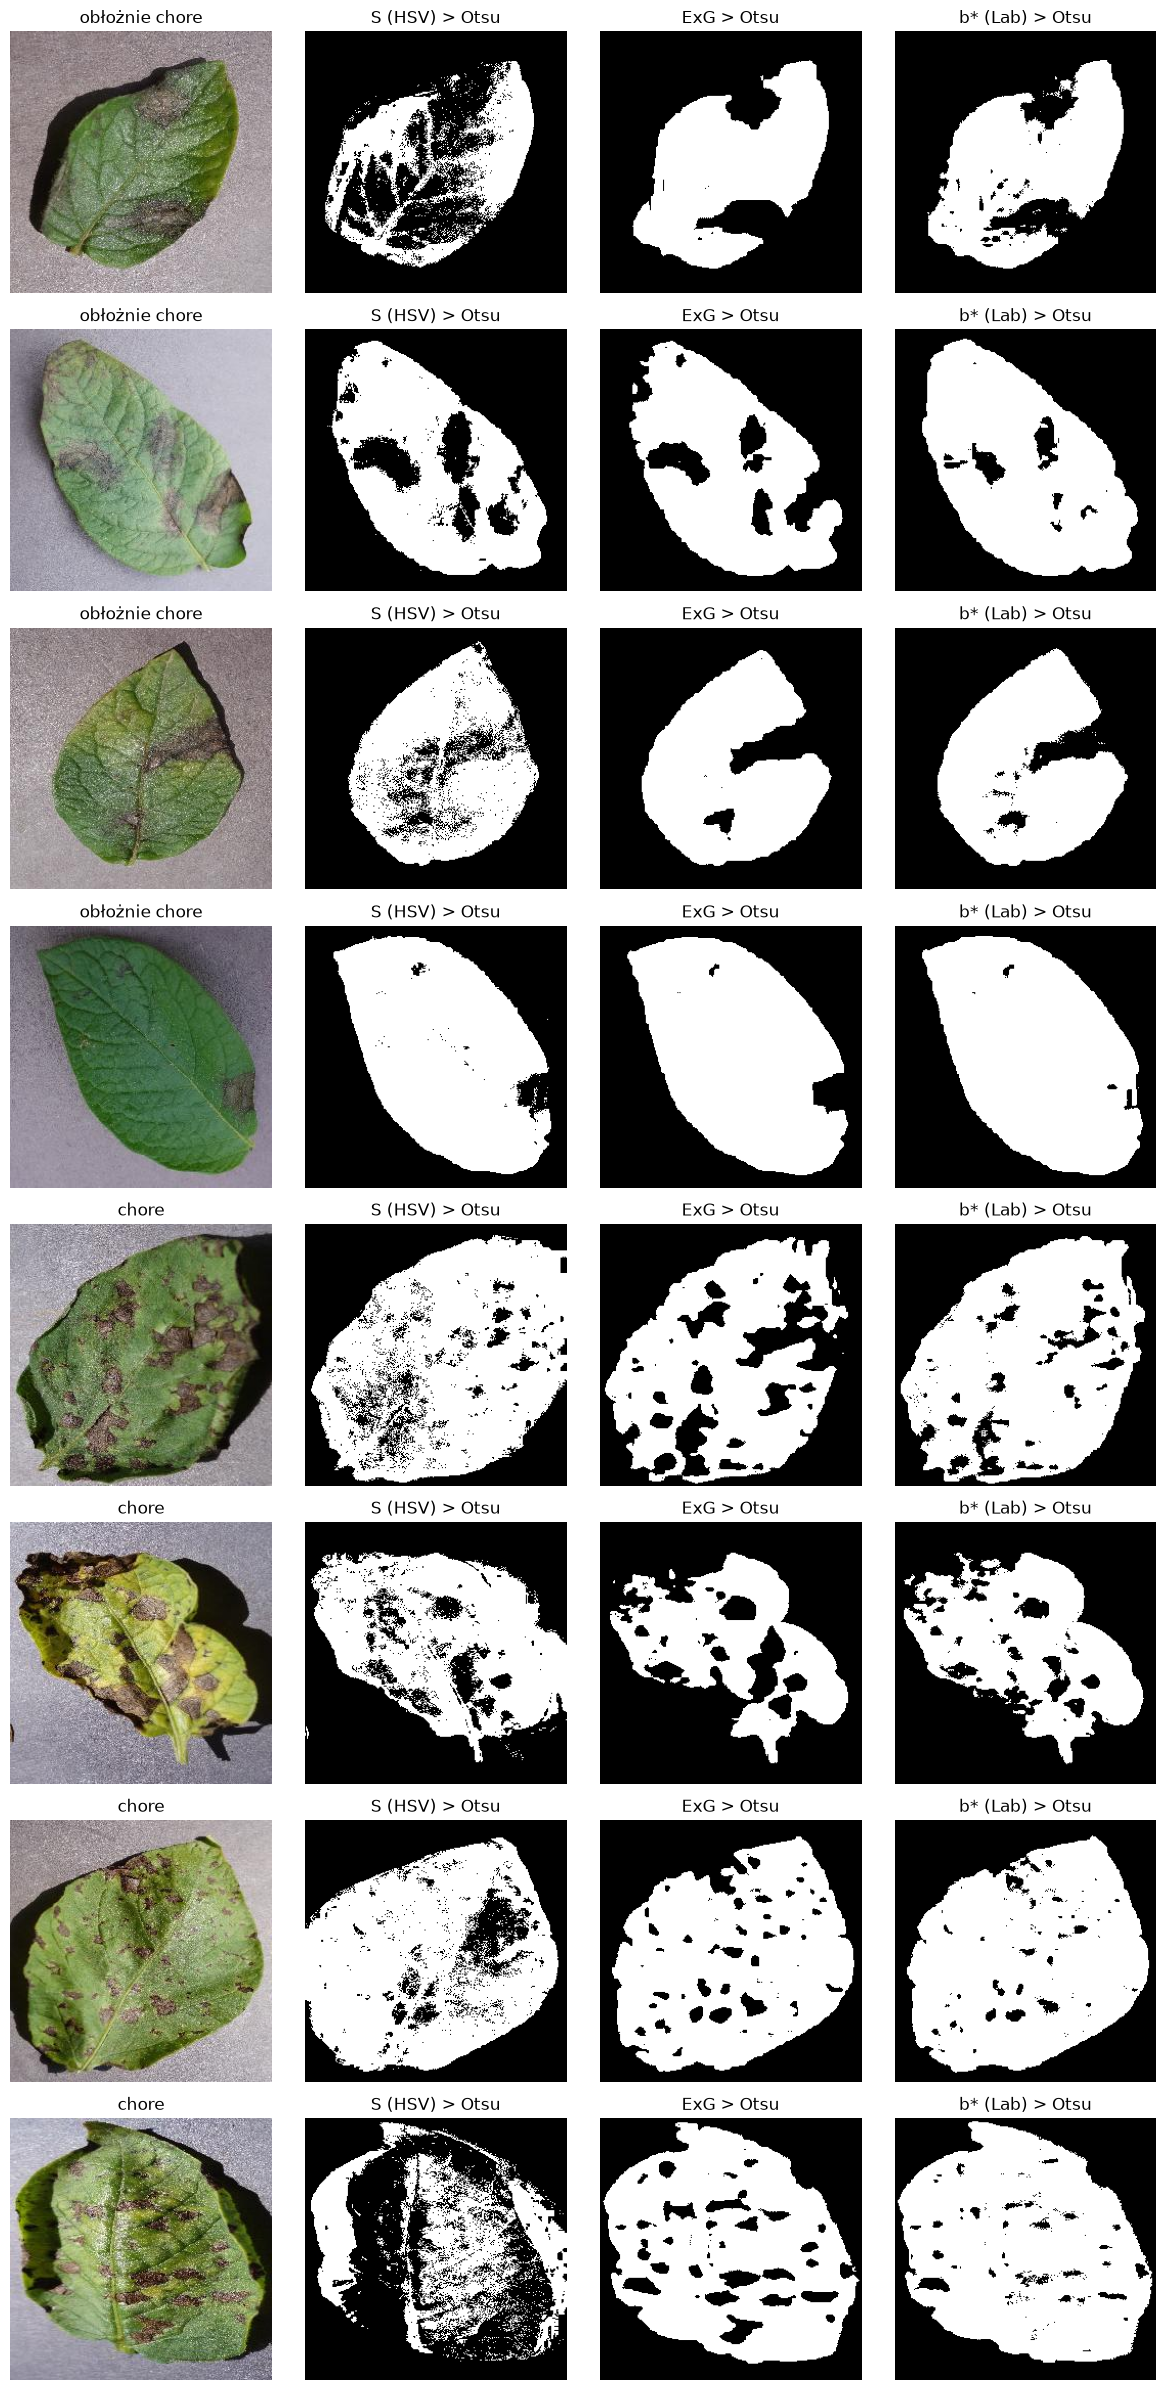

In [2]:
def channels(img):
    return {
        "S (HSV)": color.rgb2hsv(img)[..., 1],
        "ExG": lu.excess_green(img),
        "b* (Lab)": color.rgb2lab(img)[..., 2],
    }

fig, axes = plt.subplots(len(samples), 4, figsize=(12, 3 * len(samples)))
for row, (label, _, img) in zip(axes, samples):
    row[0].imshow(img)
    row[0].set_title(label)
    for ax, (name, ch) in zip(row[1:], channels(img).items()):
        ax.imshow(ch > filters.threshold_otsu(ch), cmap="gray")
        ax.set_title(f"{name} > Otsu")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

S jest za bardzo zaszumione (wzór nerwów, odblaski). ExG i b\* dają zwarty liść,
ale ExG lepiej oddziela tło z cieniem. Plamy choroby (brązowe) **nie są zielone**,
więc w masce ExG pojawiają się jako dziury, co wykorzystamy w punkcie 3.

## 2. Krok po kroku dla jednego liścia

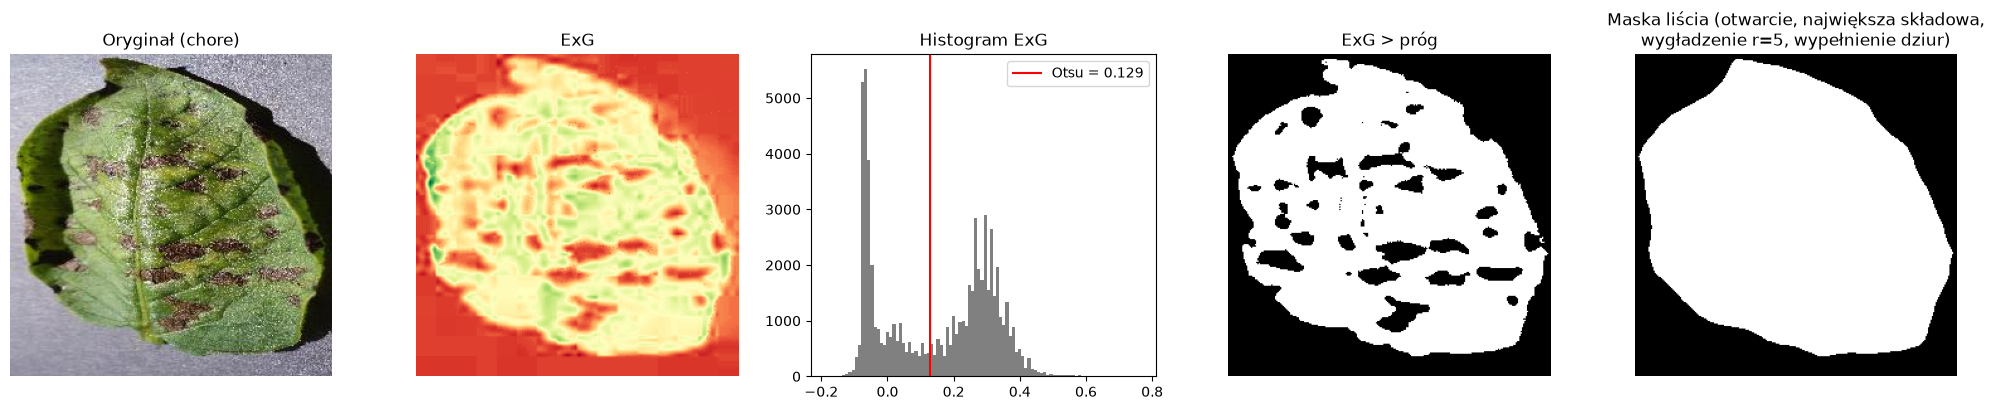

In [ ]:
label, _, img = samples[-1]  # chory liść
exg = lu.excess_green(img)
thr = filters.threshold_otsu(exg)
seg = lu.segment_leaf(img, smooth_radius=SMOOTH_RADIUS)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].imshow(img); axes[0].set_title(f"Oryginał ({label})")
axes[1].imshow(exg, cmap="RdYlGn"); axes[1].set_title("ExG")
axes[2].hist(exg.ravel(), bins=100, color="gray")
axes[2].axvline(thr, color="r", label=f"Otsu = {thr:.3f}")
axes[2].legend(); axes[2].set_title("Histogram ExG")
axes[3].imshow(seg["green"], cmap="gray"); axes[3].set_title("ExG > próg")
axes[4].imshow(seg["leaf"], cmap="gray")
axes[4].set_title(f"Maska liścia (otwarcie, największa składowa,\nwygładzenie r={SMOOTH_RADIUS}, wypełnienie dziur)")
for ax in axes[[0, 1, 3, 4]]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Wygładzanie konturu

Najpierw **dylatacja**, potem **erozja** tym samym dyskiem o promieniu `SMOOTH_RADIUS`, czyli zamknięcie morfologiczne.
Dylatacja zalewa wcięcia i szczeliny na brzegu, a erozja przywraca pierwotny rozmiar liścia.
Za duży promień zlewa głębokie wcięcia (np. przy ogonku) i dokleja do liścia fragmenty tła.

Porównanie kilku promieni (czerwony kontur = bez wygładzania, żółty = po wygładzeniu):

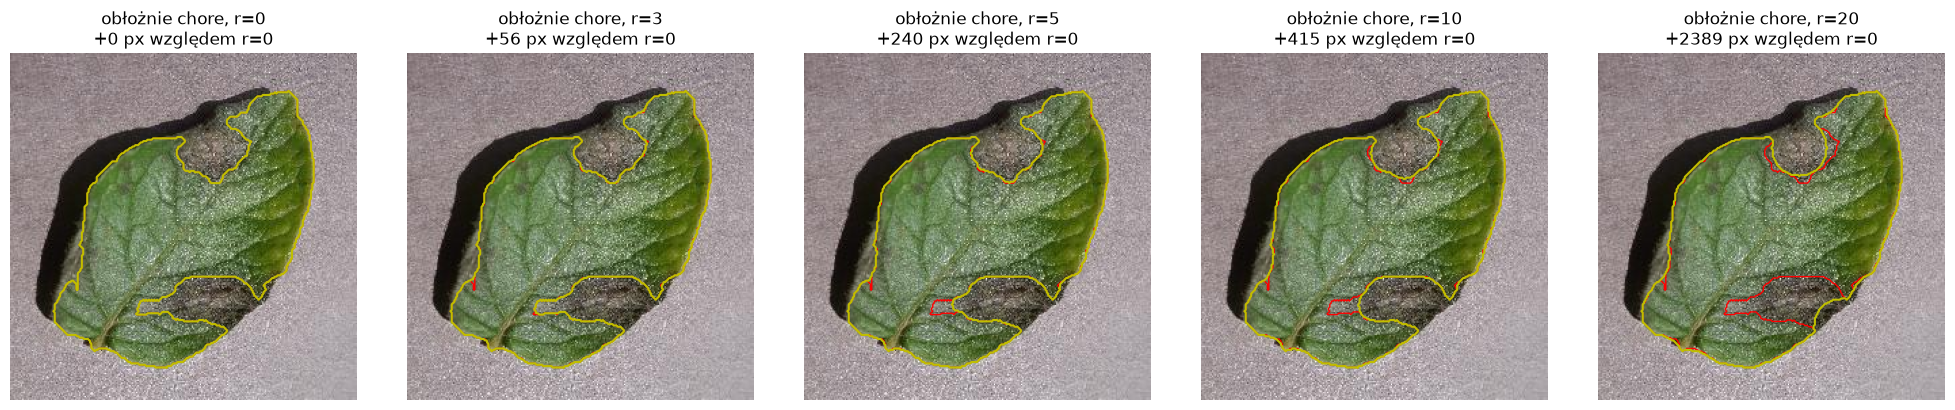

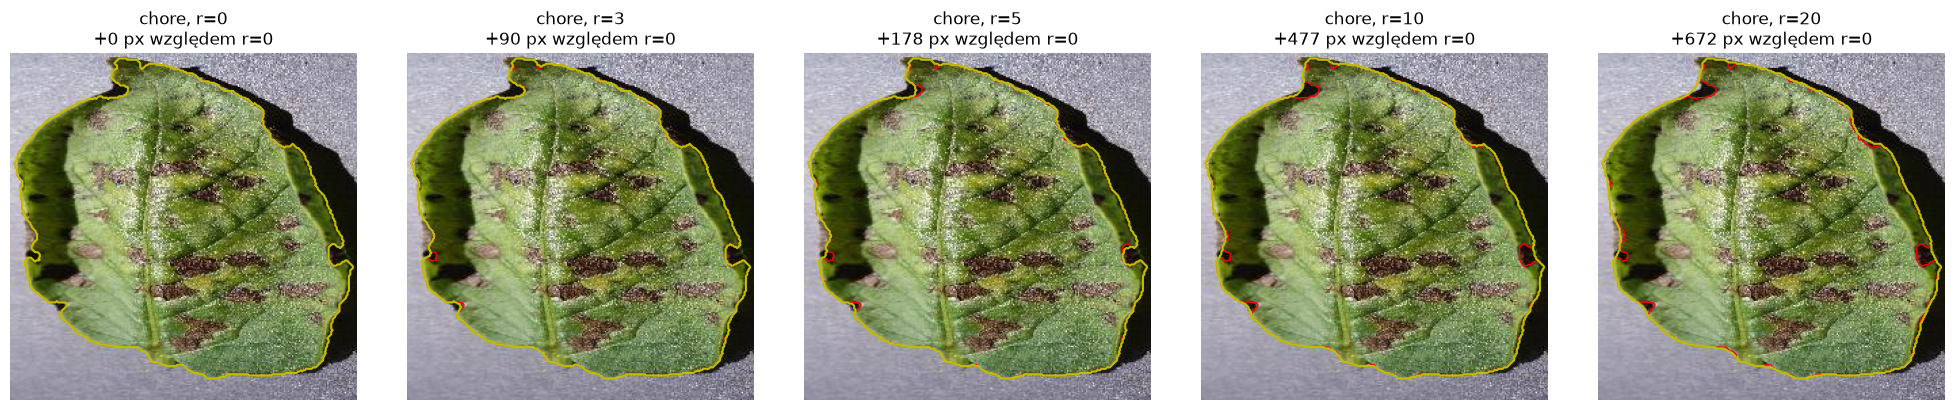

In [4]:
RADII = [0, 3, SMOOTH_RADIUS, 10, 20]

for label, _, img in [samples[0], samples[-1]]:
    raw = lu.segment_leaf(img, smooth_radius=0)["leaf"]
    fig, axes = plt.subplots(1, len(RADII), figsize=(4 * len(RADII), 4))
    for ax, r in zip(axes, RADII):
        leaf = lu.segment_leaf(img, smooth_radius=r)["leaf"]
        ax.imshow(img)
        for c in measure.find_contours(raw.astype(float), 0.5):
            ax.plot(c[:, 1], c[:, 0], "r-", linewidth=1)
        for c in measure.find_contours(leaf.astype(float), 0.5):
            ax.plot(c[:, 1], c[:, 0], "y-", linewidth=1.5)
        added = (leaf & ~raw).sum()
        ax.set_title(f"{label}, r={r}\n+{added} px względem r=0")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 3. Maska, plamy i wycięty liść dla wszystkich przykładów

- **maska liścia** – cały liść z wypełnionymi dziurami,
- **plamy** = maska liścia ∧ ¬(zielone) – obszary liścia, które nie są zielone,
- **wycięty liść** – tło wyzerowane, kadr przycięty do prostokąta otaczającego.

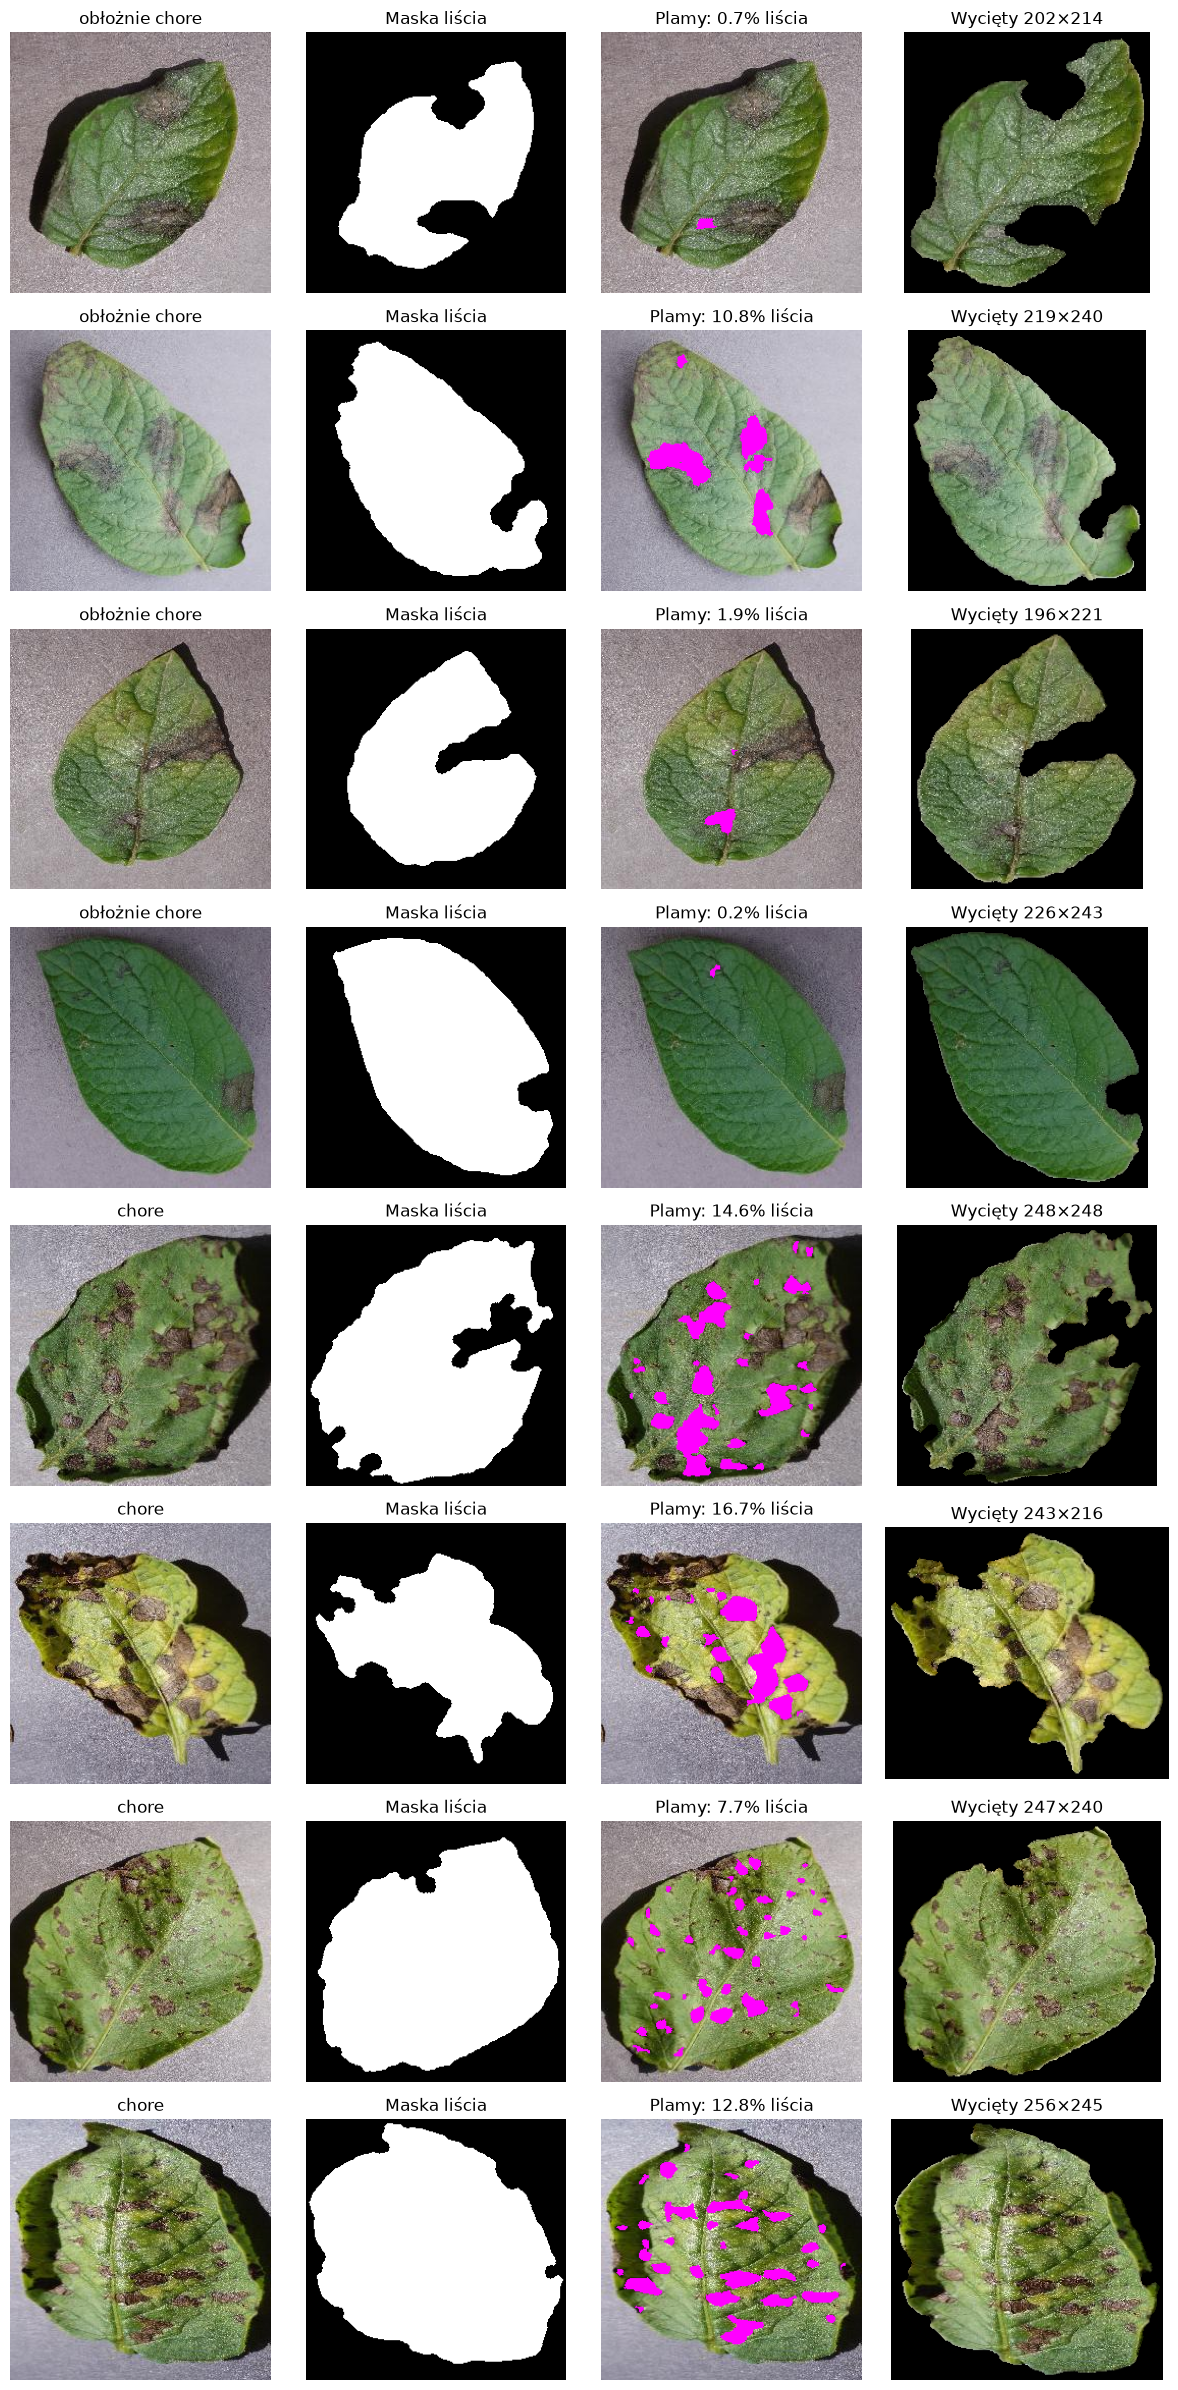

In [5]:
fig, axes = plt.subplots(len(samples), 4, figsize=(12, 3 * len(samples)))
for row, (label, _, img) in zip(axes, samples):
    seg = lu.segment_leaf(img, smooth_radius=SMOOTH_RADIUS)
    cropped, _ = lu.crop_leaf(img, seg["leaf"])
    lesion_frac = seg["lesions"].sum() / seg["leaf"].sum()

    overlay = img.copy()
    overlay[seg["lesions"]] = [255, 0, 255]

    row[0].imshow(img); row[0].set_title(label)
    row[1].imshow(seg["leaf"], cmap="gray"); row[1].set_title("Maska liścia")
    row[2].imshow(overlay); row[2].set_title(f"Plamy: {lesion_frac:.1%} liścia")
    row[3].imshow(cropped); row[3].set_title(f"Wycięty {cropped.shape[1]}×{cropped.shape[0]}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Udział plam na całym zbiorze Task 1

Szybkie sprawdzenie, czy sam udział plam rozdziela klasy.

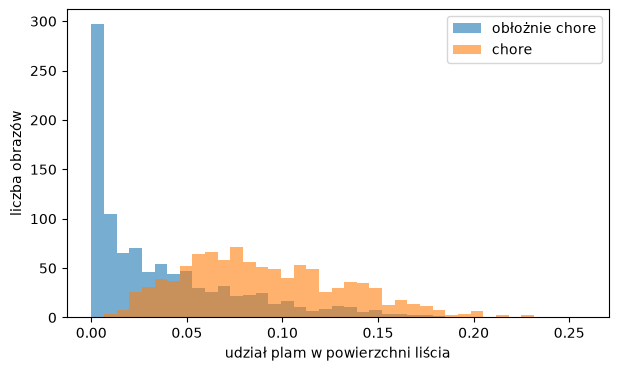

Najlepszy próg: 0.0476 -> trafność 77.0%


In [6]:
labels, fracs = [], []
for label, path in lu.list_paths():
    seg = lu.segment_leaf(lu.load(path), smooth_radius=SMOOTH_RADIUS)
    labels.append(label)
    fracs.append(seg["lesions"].sum() / seg["leaf"].sum())
labels, fracs = np.array(labels), np.array(fracs)

plt.figure(figsize=(7, 4))
bins = np.linspace(0, fracs.max(), 40)
for label in lu.CLASSES:
    plt.hist(fracs[labels == label], bins=bins, alpha=0.6, label=label)
plt.xlabel("udział plam w powierzchni liścia")
plt.ylabel("liczba obrazów")
plt.legend()
plt.show()

y = labels == "chore"
best_t = max(np.unique(fracs), key=lambda t: np.mean((fracs > t) == y))
print(f"Najlepszy próg: {best_t:.4f} -> trafność {np.mean((fracs > best_t) == y):.1%}")

Uwaga: próg dobrany na tych samych danych zawyża trafność. Do rzetelnej oceny trzeba
osobnego zbioru testowego albo walidacji krzyżowej.